# Задача 1. Геометрия детектора

Создать сферический детектор с параметрами $R=2$ м, $N=40$,
$r=0{,}10$ м и $a=0{,}5$. Расположить ФЭУ достаточно равномерно,
сохранить координаты и реализовать проверку принадлежности точки фотокатоду.

Реализация класса находится в [detector.py](detector.py).
Все координаты и длины задаются в метрах.

Для размещения центров используем сферическую решётку Фибоначчи:
$z_i=1-2(i+1/2)/N$, $\varphi_i=\pi(3-\sqrt5)i$.
Координаты сохраняются в массиве NumPy формы $(N,3)$.

**Геометрическое приближение этой версии.** Чувствительная область ФЭУ
моделируется участком сферы $|\mathbf q-\mathbf c_i|\le r$, где $r$
измеряется по хорде. В общей концепции указан плоский фотокатод;
здесь используется приближение малой чувствительной области при $r/R=0{,}05$.
Точное пересечение луча с отдельной плоской площадкой в эту реализацию
не входит. Это допущение также используется в следующих задачах.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from detector import Detector
%matplotlib inline

detector = Detector(R=2.0, N=40, r=0.10, a=0.5)
print('Размер массива координат:', detector.pmt_positions.shape)
print('Первые пять центров ФЭУ, м:')
print(np.round(detector.pmt_positions[:5], 6))
print('Диапазон расстояний до центра сферы:',
      np.linalg.norm(detector.pmt_positions, axis=1).min(),
      np.linalg.norm(detector.pmt_positions, axis=1).max())
np.savetxt('pmt_positions.csv', detector.pmt_positions,
           delimiter=',', header='x_m,y_m,z_m', comments='')

Размер массива координат: (40, 3)
Первые пять центров ФЭУ, м:
[[ 0.44441   0.        1.95    ]
 [-0.560352  0.513328  1.85    ]
 [ 0.08465  -0.964538  1.75    ]
 [ 0.687697  0.89698   1.65    ]
 [-1.244601 -0.220152  1.55    ]]
Диапазон расстояний до центра сферы: 1.9999999999999998 2.0


Метод `find_pmt(point)` сначала проверяет $|\mathbf q|=R$, затем ищет
ближайший центр ФЭУ. При расстоянии не более $r$ возвращается индекс
фотоумножителя, иначе — `None`. `is_on_pmt` возвращает логический результат.

In [2]:
points = {
    'Центр первого ФЭУ': detector.pmt_positions[0],
    'Северный полюс сферы': np.array([0.0, 0.0, detector.R]),
    'Центр детектора': np.zeros(3),
}
for label, point in points.items():
    print(f'{label}: индекс = {detector.find_pmt(point)}, '
          f'попадание = {detector.is_on_pmt(point)}')
assert all(detector.find_pmt(p) == i
           for i, p in enumerate(detector.pmt_positions))

Центр первого ФЭУ: индекс = 0, попадание = True
Северный полюс сферы: индекс = None, попадание = False
Центр детектора: индекс = None, попадание = False


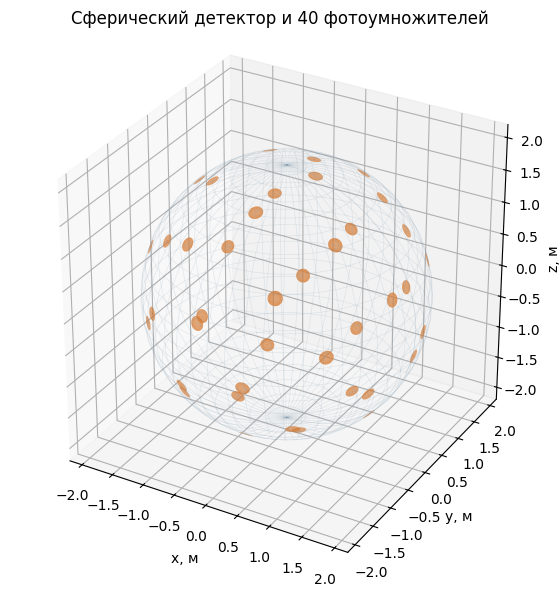

In [3]:
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection='3d')
phi, theta = np.meshgrid(np.linspace(0, 2*np.pi, 48),
                         np.linspace(0, np.pi, 25))
ax.plot_wireframe(detector.R*np.sin(theta)*np.cos(phi),
                  detector.R*np.sin(theta)*np.sin(phi),
                  detector.R*np.cos(theta), color='#86A0B4',
                  alpha=0.18, linewidth=0.5)
alpha = 2*np.arcsin(detector.r/(2*detector.R))
angles = np.arange(48)*2*np.pi/48
faces = []
for center in detector.pmt_positions:
    normal = center/detector.R
    reference = np.eye(3)[np.argmin(np.abs(normal))]
    u = np.cross(normal, reference)
    u /= np.linalg.norm(u)
    v = np.cross(normal, u)
    ring = detector.R*(np.cos(alpha)*normal + np.sin(alpha)*(
        np.cos(angles)[:, None]*u + np.sin(angles)[:, None]*v))
    faces.extend([[center, ring[j], ring[(j+1) % len(ring)]]
                  for j in range(len(ring))])
ax.add_collection3d(Poly3DCollection(faces, facecolor='#D67C35',
                                    edgecolor='none', alpha=0.95))
ax.set(xlim=(-2.2, 2.2), ylim=(-2.2, 2.2), zlim=(-2.2, 2.2),
       xlabel='x, м', ylabel='y, м', zlabel='z, м',
       title='Сферический детектор и 40 фотоумножителей')
ax.set_box_aspect((1, 1, 1))
ax.zaxis.set_rotate_label(False)
ax.set_zlabel('z, м', rotation=90, labelpad=4)
Path('figures').mkdir(exist_ok=True)
fig.savefig('figures/detector_geometry.png', dpi=150, bbox_inches='tight')
plt.show()

Координаты всех 40 центров сохранены в `pmt_positions.csv`.
Статический график встроен в ноутбук и доступен без запуска интерактивных
виджетов. При необходимости интерактивный вариант предоставляется методом
`detector.visualize()` после установки необязательного пакета `k3d`.